# Fashion-MNIST Image Classification: ML Pipeline Notebook

**Goal.** Build and evaluate an image classifier for clothing items. This is the offline part of a larger ML pipeline (API, UI, Docker, cloud deployment, retraining and load testing) that lives in the same repository.

**What this notebook covers**

1. Setup and data acquisition
2. Data exploration and visualizations, with interpretations of four features of the dataset
3. Preprocessing: scaling, reshaping, train/validation split, augmentation and single-image preparation
4. Model creation: a baseline dense network and an optimized CNN
5. Training and learning curves
6. Evaluation: accuracy, precision, recall, F1, ROC-AUC, confusion matrix and per-class results
7. Prediction functions and tests on saved images
8. Saving the model and metrics

The image preparation, training and prediction logic here is the same logic used in `src/preprocessing.py`, `src/model.py` and `src/prediction.py`, which the API uses.

> **Tip:** use a GPU runtime (Runtime > Change runtime type > T4 GPU). Training the CNN then takes minutes instead of about an hour on a CPU.

## 1. Setup

We import the libraries, fix the random seeds so the results are reproducible, and define where the data and the model are saved. When this notebook sits in the repository's `notebook/` folder, `../data` and `../models` are the repository's `data/` and `models/` folders.

In [1]:
import os, glob, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize
from tensorflow.keras import layers, regularizers

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "../data"
MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


## 2. Data acquisition

We use **Fashion-MNIST**: 70,000 grayscale images of clothing, each 28 x 28 pixels, in 10 classes. It is split into 60,000 training and 10,000 test images. The data is images, not a table, and it is small enough to train and retrain quickly, which suits a pipeline that has to be retrained on demand.

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training images:", X_train.shape, "| labels:", y_train.shape)
print("Testing images :", X_test.shape, "| labels:", y_test.shape)
print("Pixel type and range:", X_train.dtype, X_train.min(), "to", X_train.max())
print("Number of classes:", len(class_names))
for index, name in enumerate(class_names):
    print(index, ":", name)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28) | labels: (60000,)
Testing images : (10000, 28, 28) | labels: (10000,)
Pixel type and range: uint8 0 to 255
Number of classes: 10
0 : T-shirt/top
1 : Trouser
2 : Pullover
3 : Dress
4 : Coat
5 : Sandal
6 : Shirt
7 : Sneaker
8 : Bag
9 : Ankle boot


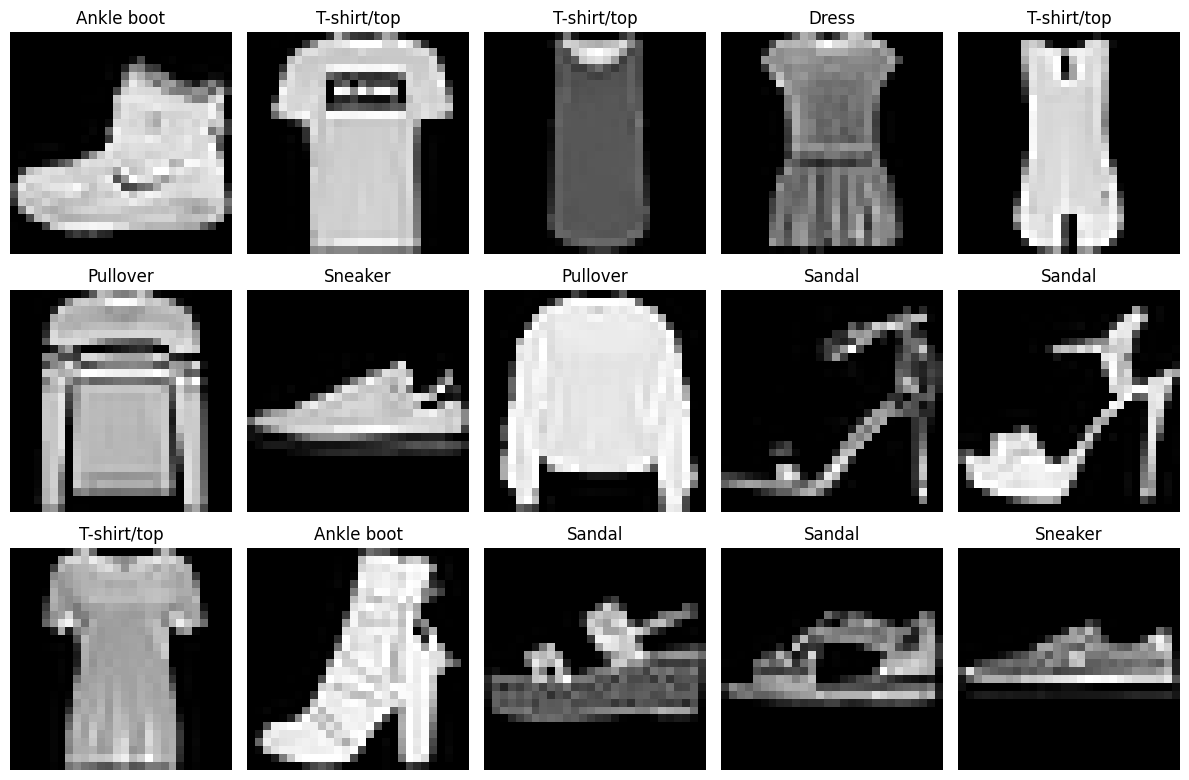

In [3]:
plt.figure(figsize=(12, 8))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Exploration and visualizations

We look at four features of the dataset and interpret each one: the class distribution, the average image of each class, the average brightness of each class, and the distribution of pixel intensities.

### Feature 1: class distribution

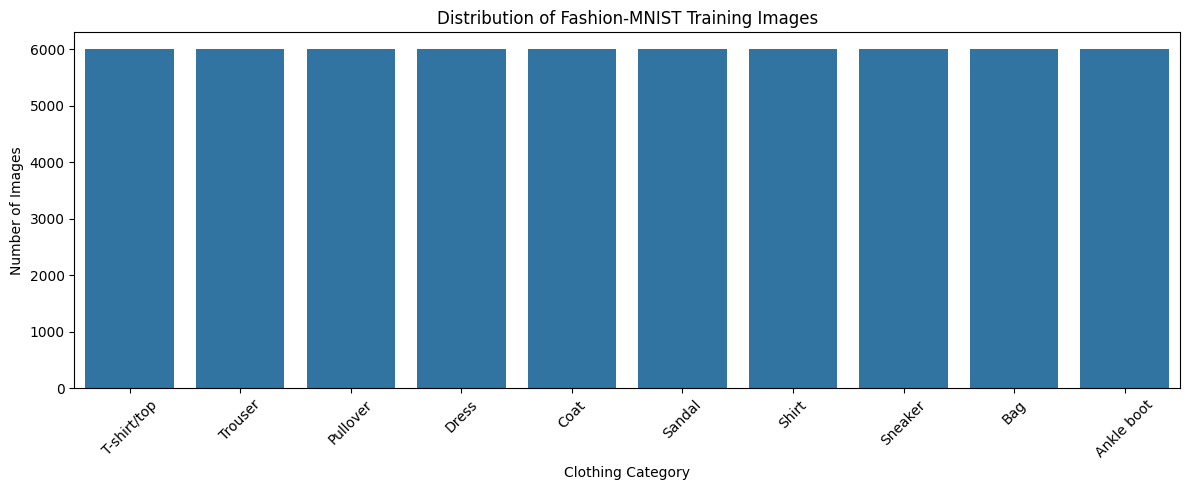

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images
Test images per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [4]:
class_counts = np.bincount(y_train, minlength=10)

plt.figure(figsize=(12, 5))
sns.barplot(x=class_names, y=class_counts)
plt.title("Distribution of Fashion-MNIST Training Images")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count} images")
print("Test images per class:", np.bincount(y_test, minlength=10))

**Interpretation.** Every class has exactly 6,000 training images and 1,000 test images, so the dataset is perfectly balanced. This means we do not need class weights or resampling, and **accuracy is a fair metric**: a model cannot score well just by favouring a large class. It also means that any difference in performance between classes comes from how hard the classes are to tell apart, not from how much data each has.

### Saving PNG copies of the images

The API, the UI and the retraining step work with image files organized in one folder per class. We therefore save part of the data as PNG files: 500 images per class for training and 100 per class for testing. This keeps the GitHub repository small.

In [5]:
def save_split(X, y, split_dir, limit_per_class=None):
    counts = {}
    for img, label in zip(X, y):
        name = class_names[label].replace("/", "-")
        counts[name] = counts.get(name, 0)
        if limit_per_class and counts[name] >= limit_per_class:
            continue
        folder = os.path.join(split_dir, name)
        os.makedirs(folder, exist_ok=True)
        Image.fromarray(img).save(os.path.join(folder, f"{counts[name]}.png"))
        counts[name] += 1


save_split(X_train, y_train, f"{DATA_DIR}/train", limit_per_class=500)
save_split(X_test, y_test, f"{DATA_DIR}/test", limit_per_class=100)

for split in ["train", "test"]:
    n = len(glob.glob(f"{DATA_DIR}/{split}/*/*.png"))
    print(split, "PNG images saved:", n)

train PNG images saved: 5000
test PNG images saved: 1000


### Feature 2: average image per class

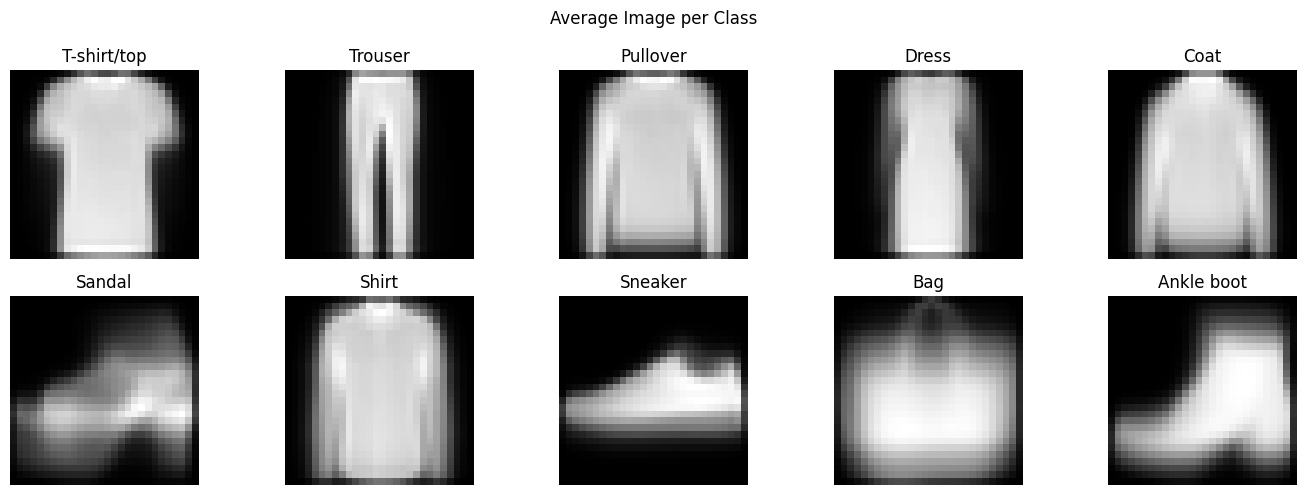

In [6]:
plt.figure(figsize=(14, 5))
for i, name in enumerate(class_names):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[y_train == i].mean(axis=0), cmap="gray")
    plt.title(name)
    plt.axis("off")
plt.suptitle("Average Image per Class")
plt.tight_layout()
plt.show()

**Interpretation.** Averaging all the images of a class shows its typical shape. Trousers, sandals, sneakers, ankle boots and bags have sharp, distinctive averages, because every item of the class has a similar outline. T-shirts, shirts, pullovers and coats have blurry averages that look alike: they share the same body-and-sleeves outline and differ only in small details such as collars, buttons and sleeve length. We therefore expect the model to classify footwear, trousers and bags easily and to **confuse the upper-body garments with each other**. The evaluation section checks this.

### Feature 3: average brightness per class

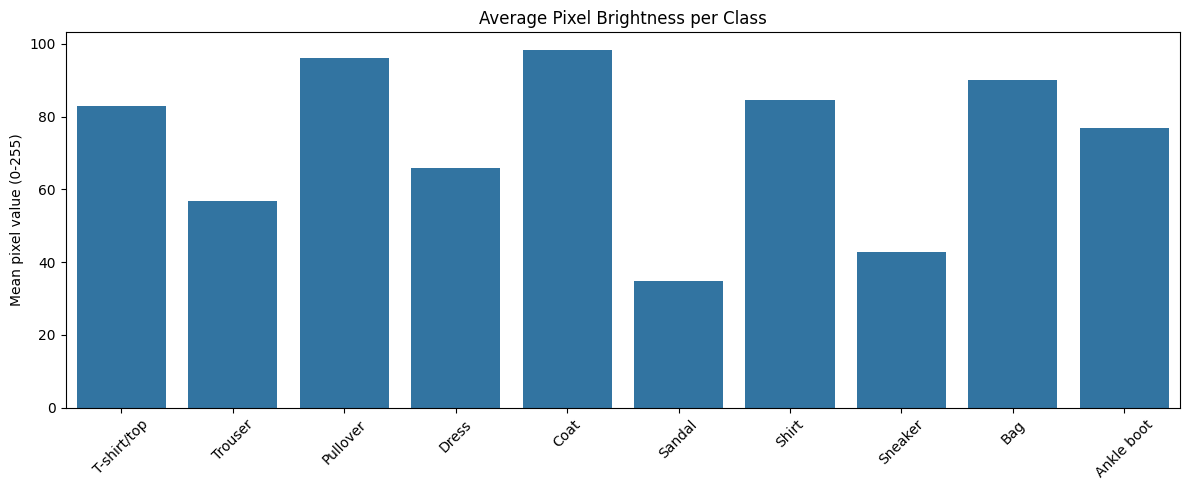

T-shirt/top: 83.0
Trouser: 56.8
Pullover: 96.1
Dress: 66.0
Coat: 98.3
Sandal: 34.9
Shirt: 84.6
Sneaker: 42.8
Bag: 90.2
Ankle boot: 76.8


In [7]:
mean_brightness = [X_train[y_train == i].mean() for i in range(10)]

plt.figure(figsize=(12, 5))
sns.barplot(x=class_names, y=mean_brightness)
plt.title("Average Pixel Brightness per Class")
plt.ylabel("Mean pixel value (0-255)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for name, value in zip(class_names, mean_brightness):
    print(f"{name}: {value:.1f}")

**Interpretation.** Coats (about 98) and pullovers (about 96) are the brightest classes because they fill much of the 28 x 28 frame. Bags (about 90) are also bright because they are large, solid objects. Sandals (about 35) and sneakers (about 43) are the darkest because they are small, thin or open objects that leave most of the image as black background. Brightness is therefore a rough proxy for how much of the frame the object fills, and it can separate footwear from tops. It **cannot separate similar tops** (T-shirt about 83, Shirt about 84.5, Pullover about 96, Coat about 98), whose values are close. Confusion among those classes is expected.

### Feature 4: pixel intensity distribution

We compare three classes with very different shapes: Trouser, Sandal and Bag. We take a random sample of pixels from each class, and we restrict the curve to the valid range 0 to 255.

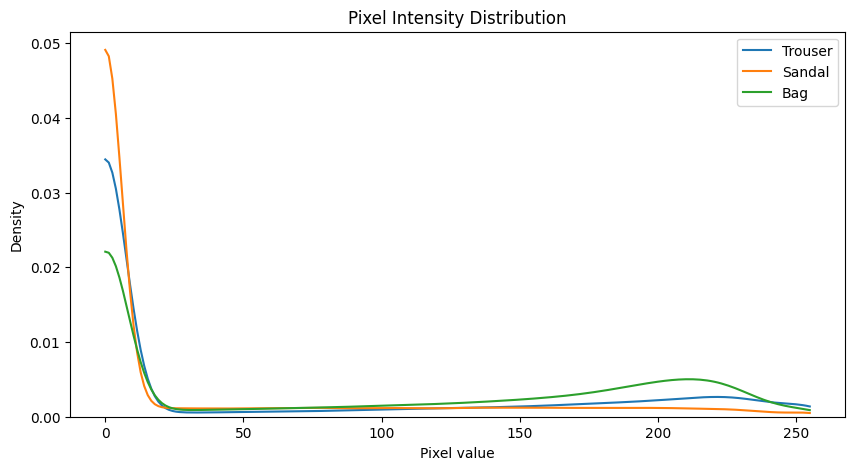

In [8]:
plt.figure(figsize=(10, 5))
rng = np.random.default_rng(SEED)
for i in [1, 5, 8]:  # Trouser, Sandal, Bag
    pixels = X_train[y_train == i].flatten()
    sample = rng.choice(pixels, 200000, replace=False)
    sns.kdeplot(sample, label=class_names[i], clip=(0, 255))
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel value")
plt.legend()
plt.show()

**Interpretation.** All three classes have a large spike at 0, which is the black background. The sandal has the tallest spike and the lowest bright tail, which means that it is mostly empty image with few bright pixels. The bag has the lowest background spike and the heaviest bright tail, showing large, uniformly bright regions. The trouser falls in between. The distribution of pixel values therefore reflects how much of the frame an item fills and how solid it is, and this gives the model useful information in addition to the outline.

## 4. Preprocessing

The steps, and the reason for each:

1. **Scale pixels to the range 0 to 1** (divide by 255). Small, consistent input values make training faster and more stable.
2. **Add a channel dimension**, so each image has shape 28 x 28 x 1. Convolution layers expect a channel axis (1 for grayscale).
3. **Split into training and validation sets** (90% / 10%, stratified so each class keeps the same share). The model never trains on the validation images, so they show whether it generalizes. The 10,000 test images stay untouched until the final evaluation.
4. **Augmentation (training only).** Random horizontal flips, small rotations and zooms create slightly different versions of each image in every epoch. This acts like extra data and reduces overfitting. We do not use vertical flips, because an upside-down shoe is not a realistic input.
5. **Single-image preparation for new images** (used by the API for uploaded photos): convert to grayscale, pad to a square without squashing, resize to 28 x 28, and invert the colors if the background is light, because Fashion-MNIST items are light on a dark background.

In [9]:
X_train_n = (X_train / 255.0).reshape(-1, 28, 28, 1).astype("float32")
X_test_n = (X_test / 255.0).reshape(-1, 28, 28, 1).astype("float32")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_n, y_train, test_size=0.1, stratify=y_train, random_state=SEED
)

print("Train      :", X_tr.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test_n.shape)
print("Value range after scaling:", X_tr.min(), "to", X_tr.max())
print("Images per class in validation:", np.bincount(y_val))

Train      : (54000, 28, 28, 1)
Validation : (6000, 28, 28, 1)
Test       : (10000, 28, 28, 1)
Value range after scaling: 0.0 to 1.0
Images per class in validation: [600 600 600 600 600 600 600 600 600 600]


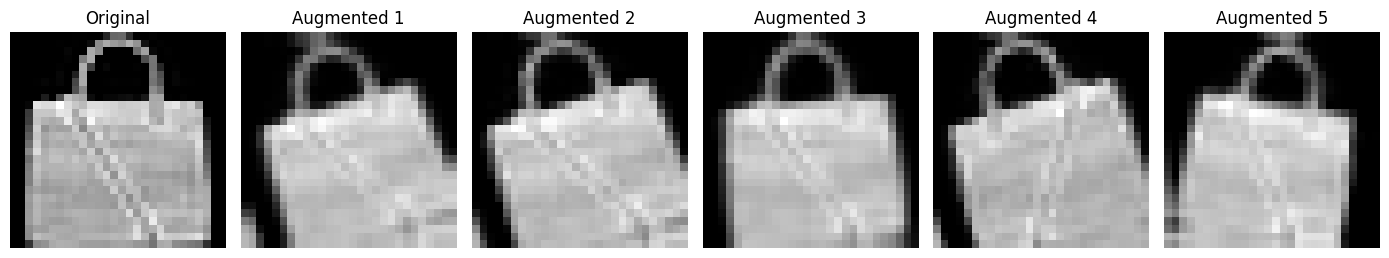

In [10]:
# Data augmentation layers (applied only while training; they are part of the model)
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

sample = X_tr[0:1]
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
axes[0].imshow(sample[0, :, :, 0], cmap="gray")
axes[0].set_title("Original")
for k in range(1, 6):
    aug = augment(sample, training=True)
    axes[k].imshow(aug[0, :, :, 0], cmap="gray")
    axes[k].set_title(f"Augmented {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

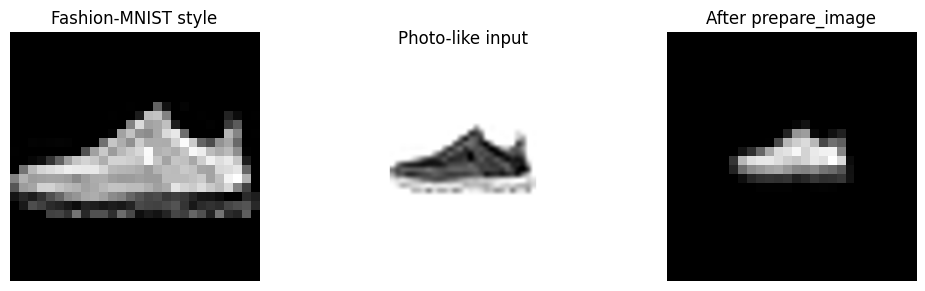

In [11]:
def prepare_image(source):
    """Turn an image path or file into a (1, 28, 28, 1) array in [0, 1]."""
    img = Image.open(source).convert("L")

    # pad to a square (instead of squashing), using the background color
    arr = np.asarray(img, dtype="float32")
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    img = ImageOps.pad(img, (28, 28), color=int(np.median(border)))

    arr = np.asarray(img, dtype="float32") / 255.0
    # Fashion-MNIST items are light on a dark background: invert light backgrounds
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    if border.mean() > 0.5:
        arr = 1.0 - arr
    return arr.reshape(1, 28, 28, 1)


# Demo: a photo-like input (dark item on a large white background, not square)
demo_src = random.choice(glob.glob(f"{DATA_DIR}/test/Sneaker/*.png"))
item = ImageOps.invert(Image.open(demo_src).convert("L")).resize((140, 140))
photo = Image.new("L", (300, 200), 255)
photo.paste(item, (80, 30))
photo.save("demo_photo.png")
processed = prepare_image("demo_photo.png")

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(Image.open(demo_src), cmap="gray")
axes[0].set_title("Fashion-MNIST style")
axes[1].imshow(photo, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Photo-like input")
axes[2].imshow(processed[0, :, :, 0], cmap="gray")
axes[2].set_title("After prepare_image")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
os.remove("demo_photo.png")

The photo-like input (a dark item on a white background, not square) is padded, resized and inverted into the same format as the training images. This is what happens to every image a user uploads through the API.

## 5. Model creation

We build two models so that we can show that the final one is actually good:

- **Baseline:** a simple dense network. It flattens the image into 784 numbers and passes them through one hidden layer of 128 neurons. It ignores the 2D structure of the image.
- **Optimized CNN:** a convolutional neural network, which learns small filters that detect local patterns (edges, then shapes, then parts of clothing). It also uses:
  - **Batch normalization**, which keeps the values inside the network well scaled and makes training stable.
  - **Dropout (0.4)**, which randomly switches off 40% of the neurons during training so the model cannot depend on any single one.
  - **L2 regularization**, which penalizes very large weights.
  - **The augmentation layers** defined above.

In [12]:
baseline = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
baseline.compile(optimizer="adam",
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])
baseline.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
cnn = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    augment,
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

## 6. Training

The baseline trains for 10 epochs. The CNN trains for up to 30 epochs with two callbacks: **early stopping** (stop when the validation loss has not improved for 4 epochs and restore the best weights) and **learning-rate reduction** (halve the learning rate when the validation loss stops improving).

In [14]:
hist_base = baseline.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=10, batch_size=64, verbose=1)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8124 - loss: 0.5395 - val_accuracy: 0.8238 - val_loss: 0.4669
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8586 - loss: 0.3987 - val_accuracy: 0.8418 - val_loss: 0.4240
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8724 - loss: 0.3581 - val_accuracy: 0.8573 - val_loss: 0.3904
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8801 - loss: 0.3319 - val_accuracy: 0.8677 - val_loss: 0.3654
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8866 - loss: 0.3118 - val_accuracy: 0.8752 - val_loss: 0.3426
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8926 - loss: 0.2946 - val_accuracy: 0.8820 - val_loss: 0.3253
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8971 - loss: 0.2812 - val_accuracy: 0.8842 - val_loss: 0.3166
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9007 - loss: 0.2695 - val_accuracy: 0.

In [15]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5),
]
hist_cnn = cnn.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                   epochs=30, batch_size=64, callbacks=callbacks, verbose=1)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7628 - loss: 0.6841 - val_accuracy: 0.8403 - val_loss: 0.4334 - learning_rate: 0.0010
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8267 - loss: 0.5070 - val_accuracy: 0.8623 - val_loss: 0.3931 - learning_rate: 0.0010
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8481 - loss: 0.4621 - val_accuracy: 0.8558 - val_loss: 0.4320 - learning_rate: 0.0010
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8571 - loss: 0.4439 - val_accuracy: 0.8953 - val_loss: 0.3435 - learning_rate: 0.0010
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8629 - loss: 0.4271 - val_accuracy: 0.8978 - val_loss: 0.3309 - learning_rate: 0.0010
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8700 - loss: 0.4106 - val_accuracy: 0.8905 - val_loss: 0.3604 - learning_rate: 0.0010
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8751 - loss: 0.3

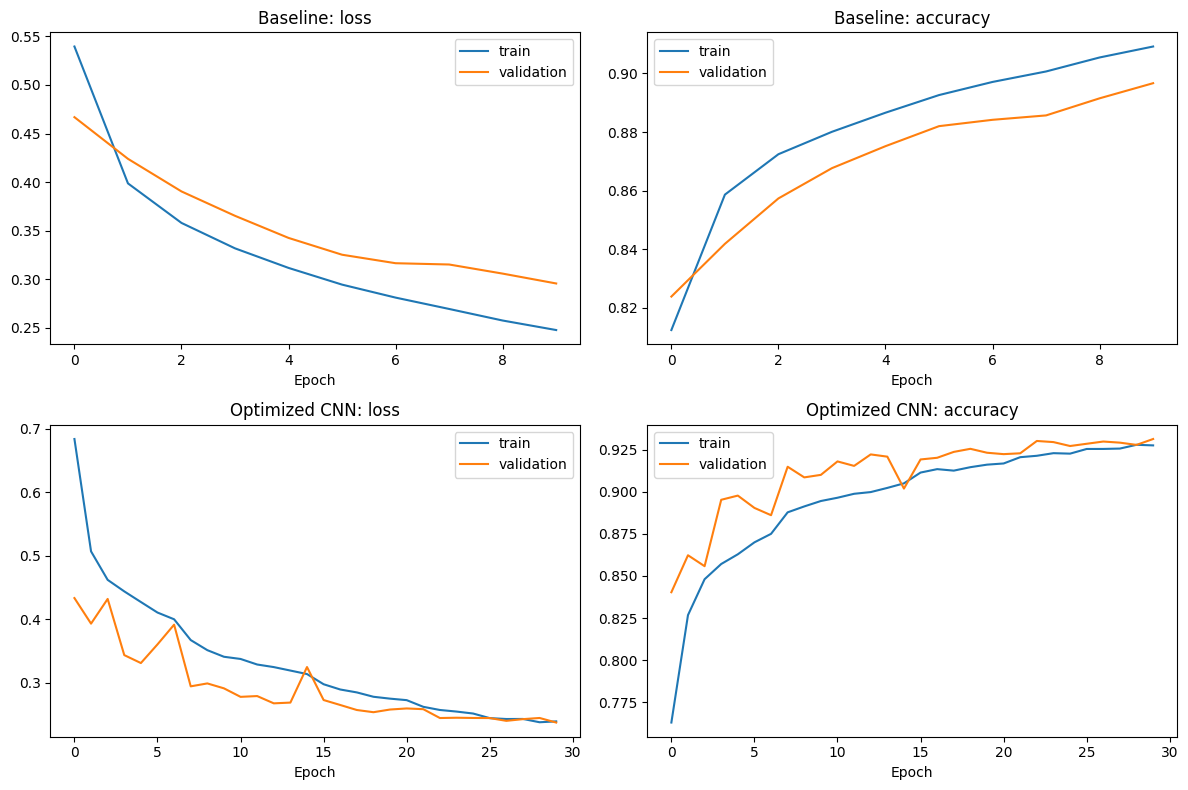

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (hist, title) in enumerate([(hist_base, "Baseline"), (hist_cnn, "Optimized CNN")]):
    axes[row, 0].plot(hist.history["loss"], label="train")
    axes[row, 0].plot(hist.history["val_loss"], label="validation")
    axes[row, 0].set_title(f"{title}: loss")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].legend()
    axes[row, 1].plot(hist.history["accuracy"], label="train")
    axes[row, 1].plot(hist.history["val_accuracy"], label="validation")
    axes[row, 1].set_title(f"{title}: accuracy")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].legend()
plt.tight_layout()
plt.show()

**Reading the curves.** If the training and validation curves end close together, the model is not overfitting (it is not memorizing the training images). For the CNN, validation accuracy can sit slightly above training accuracy in the early epochs, because dropout and augmentation are active only during training. The baseline typically shows a growing gap between training and validation accuracy, because it has no regularization.

## 7. Evaluation on the test set

We evaluate both models on the 10,000 test images, which were not used for training or validation. Metrics:

- **Accuracy:** the share of images classified correctly.
- **Precision:** of the images predicted as a class, the share that truly belongs to it.
- **Recall:** of the images that truly belong to a class, the share that the model finds.
- **F1-score:** the balance of precision and recall.
- **ROC-AUC:** how well the model ranks the right class above the others (1.0 is perfect, 0.5 is random).
- **Confusion matrix:** which classes are mistaken for which.

Precision, recall and F1 are macro-averaged: computed per class and averaged, so every class counts equally.

In [17]:
def evaluate(model, name):
    probs = model.predict(X_test_n, verbose=0)
    preds = probs.argmax(axis=1)
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision (macro)": precision_score(y_test, preds, average="macro"),
        "Recall (macro)": recall_score(y_test, preds, average="macro"),
        "F1 (macro)": f1_score(y_test, preds, average="macro"),
        "ROC-AUC (OvR)": roc_auc_score(y_test, probs, multi_class="ovr"),
    }
    return result, probs, preds


res_base, probs_base, preds_base = evaluate(baseline, "Baseline Dense")
res_cnn, probs_cnn, preds_cnn = evaluate(cnn, "Optimized CNN")

comparison = pd.DataFrame([res_base, res_cnn]).set_index("Model").round(4)
comparison

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Baseline Dense,0.8787,0.8811,0.8787,0.8792,0.9896
Optimized CNN,0.9189,0.9198,0.9189,0.9192,0.9951


In [18]:
print(classification_report(y_test, preds_cnn, target_names=class_names))

report = classification_report(y_test, preds_cnn, target_names=class_names, output_dict=True)
per_class = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score"]]
per_class.round(3)

              precision    recall  f1-score   support

 T-shirt/top       0.90      0.85      0.87      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.88      0.89      0.88      1000
       Dress       0.93      0.92      0.92      1000
        Coat       0.88      0.85      0.87      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.74      0.79      0.77      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.99      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



,precision,recall,f1-score
T-shirt/top,0.895,0.854,0.874
Trouser,0.985,0.989,0.987
Pullover,0.878,0.890,0.884
Dress,0.926,0.915,0.921
Coat,0.882,0.850,0.866
Sandal,0.987,0.981,0.984
Shirt,0.743,0.789,0.765
Sneaker,0.948,0.974,0.961
Bag,0.978,0.991,0.985
Ankle boot,0.976,0.956,0.966


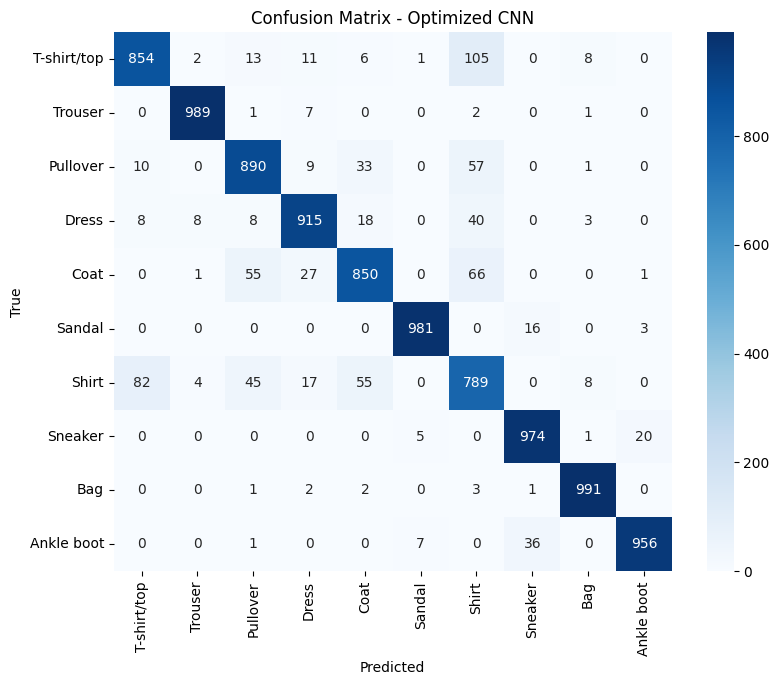

In [19]:
cm = confusion_matrix(y_test, preds_cnn)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Optimized CNN")
plt.show()

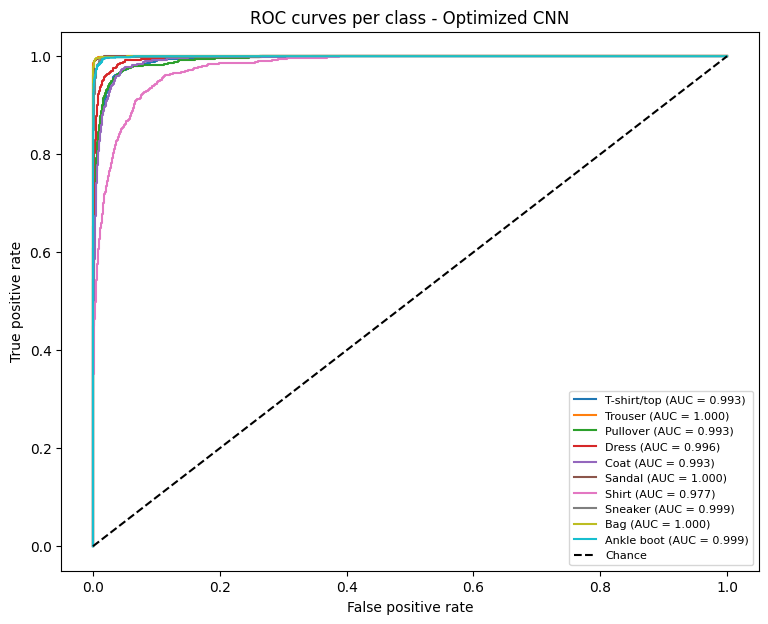

In [20]:
y_test_bin = label_binarize(y_test, classes=list(range(10)))
plt.figure(figsize=(9, 7))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs_cnn[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves per class - Optimized CNN")
plt.legend(fontsize=8)
plt.show()

In [21]:
acc_b, acc_c = res_base["Accuracy"], res_cnn["Accuracy"]
print(f"Baseline accuracy : {acc_b:.4f}")
print(f"CNN accuracy      : {acc_c:.4f}  (+{(acc_c - acc_b) * 100:.2f} points)")
print(f"Error rate        : {(1 - acc_b) * 100:.1f}% -> {(1 - acc_c) * 100:.1f}%")
print(f"CNN final train / validation accuracy: "
      f"{hist_cnn.history['accuracy'][-1]:.4f} / {hist_cnn.history['val_accuracy'][-1]:.4f}")

print("Best class   :", per_class["f1-score"].idxmax(), round(per_class["f1-score"].max(), 3))
print("Weakest class:", per_class["f1-score"].idxmin(), round(per_class["f1-score"].min(), 3))

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
print(f"Most common mistake: true {class_names[i]} predicted as {class_names[j]} "
      f"({off_diagonal[i, j]} images)")

Baseline accuracy : 0.8787
CNN accuracy      : 0.9189  (+4.02 points)
Error rate        : 12.1% -> 8.1%
CNN final train / validation accuracy: 0.9277 / 0.9315
Best class   : Trouser 0.987
Weakest class: Shirt 0.765
Most common mistake: true T-shirt/top predicted as Shirt (105 images)


**Interpretation.** The optimized CNN improves every metric over the dense baseline, so the convolutional layers and the regularization clearly help. Precision, recall and F1 are almost identical because the test set is perfectly balanced. Classes with distinctive shapes (Trouser, Sandal, Bag, Ankle boot, Sneaker) are classified almost perfectly. The weakest class is Shirt, which is mostly confused with T-shirt/top, Coat and Pullover: at 28 x 28 pixels the collar and buttons are only a few pixels wide. This matches what the average-image and brightness plots predicted. (Check the numbers printed above, because the exact figures depend on the run.)

The curves show validation loss tracking training loss closely, so the regularization (dropout, L2, augmentation) is working and the model is not overfitting.

## 8. Prediction function and tests

`predict_image` takes one image (a path) and returns the predicted class and the model's confidence. It uses `prepare_image` from the preprocessing section, so the notebook, the API and the UI prepare images in exactly the same way.

In [22]:
def predict_image(model, source):
    x = prepare_image(source)
    probs = model.predict(x, verbose=0)[0]
    idx = int(probs.argmax())
    return class_names[idx], float(probs[idx])

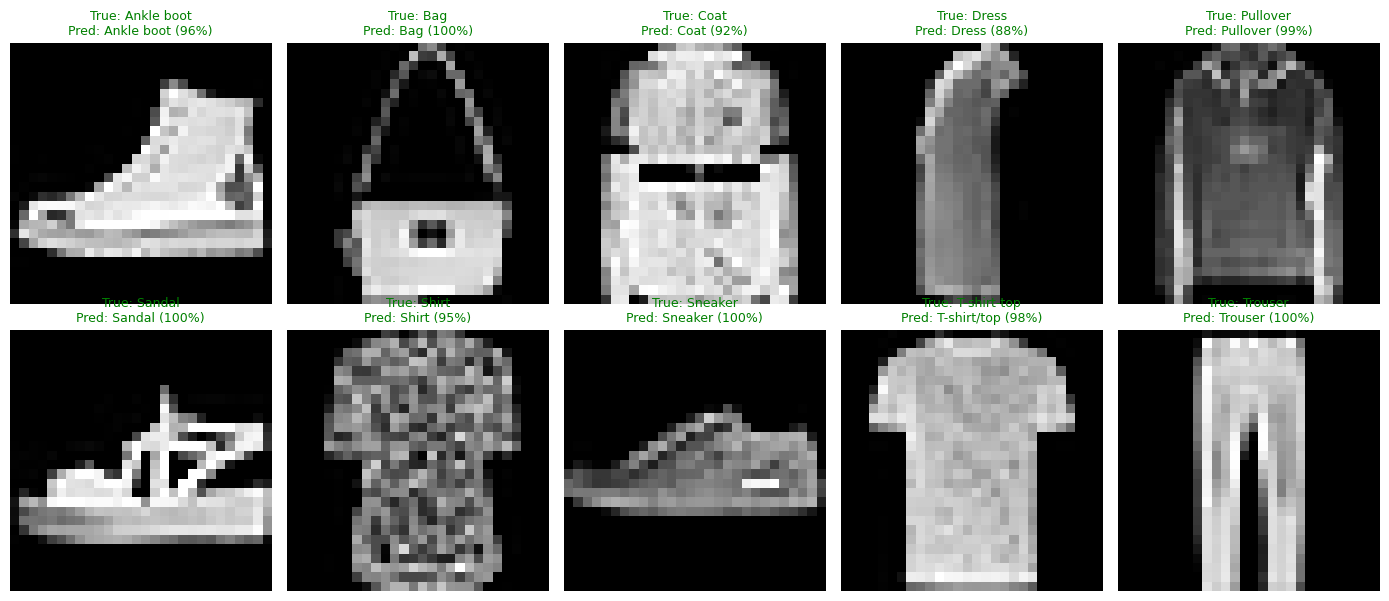

Correct: 10/10


In [23]:
# Test 1: one random saved test image per class
test_root = f"{DATA_DIR}/test"
folders = sorted(os.listdir(test_root))

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
correct = 0
for ax, folder in zip(axes.ravel(), folders):
    path = random.choice(glob.glob(os.path.join(test_root, folder, "*.png")))
    label, conf = predict_image(cnn, path)
    ok = label.replace("/", "-") == folder
    correct += ok
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(f"True: {folder}\nPred: {label} ({conf:.0%})",
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Correct: {correct}/{len(folders)}")

In [24]:
# Test 2: a white-background version of a test image (simulates a real photo)
sample_path = random.choice(glob.glob(os.path.join(test_root, "Sneaker", "*.png")))
inverted = Image.fromarray(255 - np.array(Image.open(sample_path)))
inverted.save("white_bg_test.png")
print("Original        :", predict_image(cnn, sample_path))
print("White background:", predict_image(cnn, "white_bg_test.png"))
os.remove("white_bg_test.png")

Original        : ('Sneaker', 0.9999839067459106)
White background: ('Sneaker', 0.9999839067459106)


Both predictions should give the same class with similar confidence, which shows that the preparation step handles light backgrounds correctly.

## 9. Saving the model and the metrics

The `.keras` file is what the API loads. We also save an `.h5` copy of the same model. `metrics.json` is what the dashboard shows (version, accuracy, precision, recall, F1 and the confusion matrix).

In [25]:
cnn.save(f"{MODELS_DIR}/fashion_cnn.keras")
try:
    cnn.save(f"{MODELS_DIR}/fashion_cnn.h5")
except Exception as e:
    print("Could not save the .h5 copy:", e)

metrics = {
    "accuracy": float(res_cnn["Accuracy"]),
    "precision": float(res_cnn["Precision (macro)"]),
    "recall": float(res_cnn["Recall (macro)"]),
    "f1": float(res_cnn["F1 (macro)"]),
    "confusion_matrix": cm.tolist(),
    "n_samples": int(len(y_test)),
    "model_version": 1,
    "trained_on": "fashion-mnist (train)",
}
with open(f"{MODELS_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved files:", sorted(os.listdir(MODELS_DIR)))

Saved files: ['fashion_cnn.h5', 'fashion_cnn.keras', 'metrics.json']


## 10. Conclusions and limitations

- The optimized CNN clearly outperforms the dense baseline on every metric, and its learning curves show no sign of overfitting.
- Errors are concentrated in visually similar upper-body garments, above all Shirt. This is a consequence of the 28 x 28 resolution, and the average-image plot predicted it.
- The preprocessing function used here is the same one the API uses, so uploaded photos are prepared exactly as the training images were.
- **Limitations:** the images are tiny and grayscale, so real photos are classified less accurately than test images; accuracy gains from retraining are small once the model is already strong; new data must be labelled by the user.
- **Future work:** a deeper CNN or more epochs for the hardest classes, higher-resolution data, and monitoring for data drift.

Retraining (fine-tuning on newly uploaded images) is implemented in `src/model.py` and is triggered from the UI or automatically after a number of uploads.

### Optional: download the generated files (Colab)

Run this last cell in Colab to download the `data/` and `models/` folders as one zip file.

In [26]:
import zipfile

with zipfile.ZipFile("project_files.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [DATA_DIR, MODELS_DIR]:
        for root, _, files in os.walk(folder):
            for f in files:
                path = os.path.join(root, f)
                z.write(path, os.path.relpath(path, os.path.dirname(folder)))

try:
    from google.colab import files
    files.download("project_files.zip")
except ImportError:
    print("Saved as project_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>